### A worked example behind Figure 2
You should have read the worked example for phased data Figure 1. Similarly, here is the worked example for unphased genotypes. One complication is that the two forms of the double heterozygotes cannot be differented - we only know their sum. 

The input data is the a set of nine genotype counts. 

Four estimators were run: Burrows, RG, and the two flavours of RP. Burrows was chosen because of its importance in $N_e$ estimation, and it represts the gene-counting family. EM was not considered here because 1) it had been compared to RG before (and that it was worse), and 2) EM is iterative and running it with the probe loci in RP is simply too computationally intensive. 

Again, to recreate Figure 2, you'll need to loop the function <code>f()</code> for different $s$ and underlying true $r^2$. The formuale for RG with unphased data was converted from the Mathematica notebook (supp info) from Ragsdale and Gravel. 

In [1]:
require(compiler)
enableJIT(3)

dyn.load('../cpp/unbiased_r2_2.dll')

Loading required package: compiler



[1] 3

In [2]:
initialise<-function(N, p1=0.4, p2=0.6, D=0.1)
{
    y<-.Call('initialise2', as.integer(N), as.double(p1), as.double(p2), as.double(D))
    id<-sample(1:(2*N))
    return(y[id,])
}
# SAMPLE UNPHASED, WITHOUT REPLACEMENT
sample_unphased<-function(y, s=50)
{
    N<-nrow(y)/2
    temp<-sample(1:N, size=s, replace=F)-1
    z<-.Call('sample_unphased', y, as.integer(temp))
    return(z) 
}

In [8]:
f<-function(p1=0.5, p2=0.5, D=0, s=50)
{
    # TRUE POPULATION AND TRUE r2
    y<-initialise(N=20000, p1=p1, p2=p2, D=D)
    true_r2<-.Call('mle_phased', as.raw(y[,1]), as.raw(y[,2]))
    # SIM SETTINGS
    times<-2000
    ncpu<-8; mode(ncpu)<-'integer';
    # EMPTY VECTORS TOSTORE RESULTS
    r2_burrows<-rep(NA, times)
    r2_burrows_block<-rep(NA, times)
    r2_RG<-rep(NA, times)
    r2_RG_block<-rep(NA, times)
    #
    for (i in 1:times)
    {
        # GENERATE THE DUMMY PROBE LOCI
        z<-.Call('white_noise_unphased', as.integer(s), as.double(runif(20000, 0.45, 0.55)))
        # MULTINOMIAL SAMPLING
        temp<-sample_unphased(y, s=s)
        while (is.na(.Call('burrows', as.raw(temp[,1]), as.raw(temp[,2]))))
        {temp<-sample_unphased(y, s=s)}
        # RE-ESTIAMTE r^2 WITH THE FOUR ESTIMATORS. BURROWS, RP+BURROWS, RG, RP+RG
        r2_burrows[i]<-.Call('burrows', as.raw(temp[,1]), as.raw(temp[,2]))
        r2_burrows_block[i]<-.Call('burrows_block', as.raw(temp[,1]), as.raw(temp[,2]), z, ncpu)
        r2_RG[i]<-.Call('RG_unphased', as.raw(temp[,1]), as.raw(temp[,2]))
        r2_RG_block[i]<-.Call('RG_unphased_block', as.raw(temp[,1]), as.raw(temp[,2]), z, ncpu)
    }
    # RETURN OUTPUTS
    return(list(s=s, true_r2=true_r2, times=times, 
               r2_burrows=r2_burrows, r2_burrows_block=r2_burrows_block, r2_RG=r2_RG, r2_RG_block=r2_RG_block))

}

In [10]:
# LET'S RUN IT
y<-f(p1=0.4, p2=0.05, D=0, s=50)

In [11]:
# TRUE POPULATION r^2
y$true_r2

[1] 0

In [12]:
# OUT ESTIMATE
mean(y$r2_burrows, na.rm=T)
mean(y$r2_burrows_block, na.rm=T)
mean(y$r2_RG, na.rm=T)
mean(y$r2_RG_block, na.rm=T)

[1] 0.02058538

[1] -0.0007427609

[1] -0.0006059033

[1] -0.0007329815

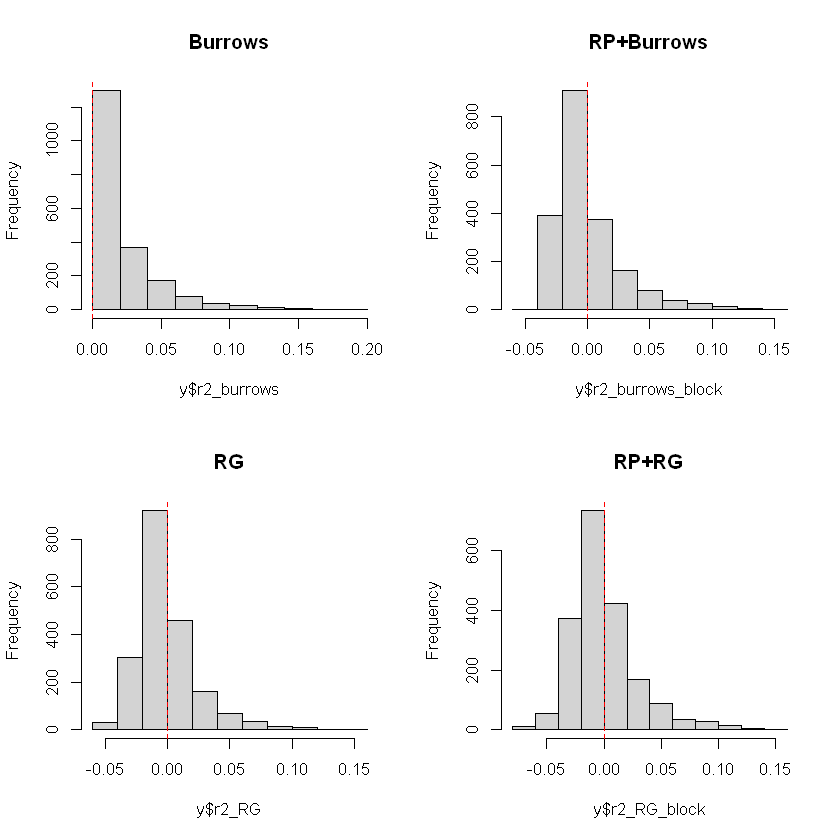

In [13]:
par(mfrow=c(2,2))
hist(y$r2_burrows, main='Burrows')
abline(v=y$true_r2, col='red', lty=2)
hist(y$r2_burrows_block, main='RP+Burrows')
abline(v=y$true_r2, col='red', lty=2)
hist(y$r2_RG, main='RG')
abline(v=y$true_r2, col='red', lty=2)
hist(y$r2_RG_block, main='RP+RG')
abline(v=y$true_r2, col='red', lty=2)

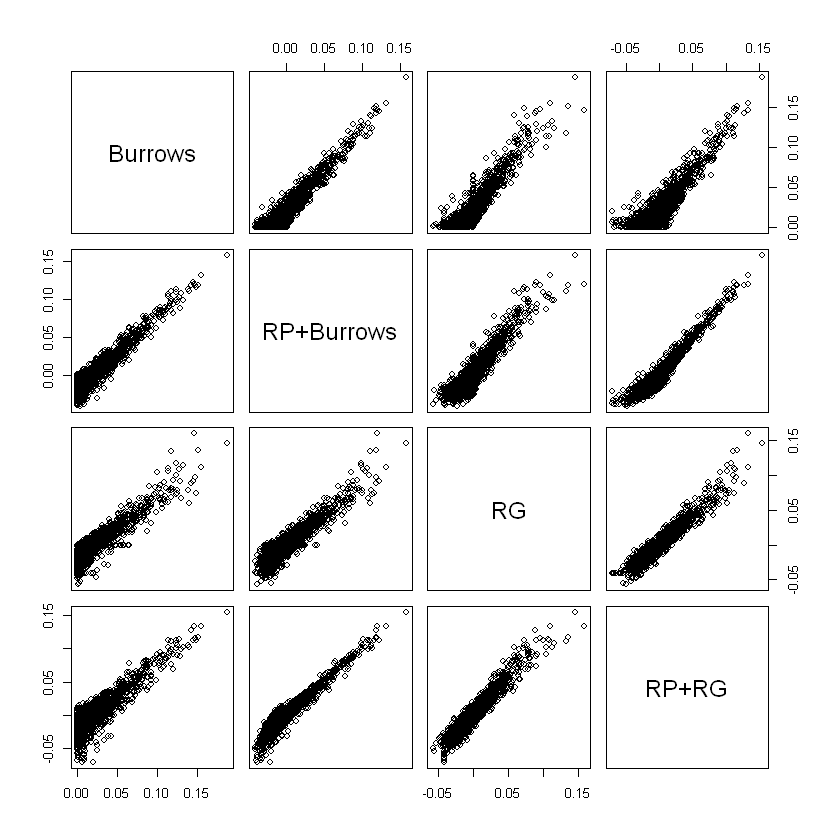

In [14]:
# PAIRWISE SCATTER PLOTS
pairs(data.frame(y$r2_burrows, y$r2_burrows_block, y$r2_RG, y$r2_RG_block), 
      labels=c('Burrows', 'RP+Burrows', 'RG', 'RP+RG'))

In [7]:
dyn.unload('../cpp/unbiased_r2_2.dll')